# **Глава 3. Классификаторы в Scikit-Learn.**

## **Работа с MNIST.**

*Загрузим датасет.*

In [1]:
from sklearn.datasets import fetch_openml

In [2]:
mnist = fetch_openml("mnist_784", version=1, cache=True, as_frame=False)
mnist

{'data': array([[0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        ...,
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0],
        [0, 0, 0, ..., 0, 0, 0]], shape=(70000, 784)),
 'target': array(['5', '0', '4', ..., '4', '5', '6'], shape=(70000,), dtype=object),
 'frame': None,
 'categories': {'class': ['0', '1', '2', '3', '4', '5', '6', '7', '8', '9']},
 'feature_names': ['pixel1',
  'pixel2',
  'pixel3',
  'pixel4',
  'pixel5',
  'pixel6',
  'pixel7',
  'pixel8',
  'pixel9',
  'pixel10',
  'pixel11',
  'pixel12',
  'pixel13',
  'pixel14',
  'pixel15',
  'pixel16',
  'pixel17',
  'pixel18',
  'pixel19',
  'pixel20',
  'pixel21',
  'pixel22',
  'pixel23',
  'pixel24',
  'pixel25',
  'pixel26',
  'pixel27',
  'pixel28',
  'pixel29',
  'pixel30',
  'pixel31',
  'pixel32',
  'pixel33',
  'pixel34',
  'pixel35',
  'pixel36',
  'pixel37',
  'pixel38',
  'pixel39',
  'pixel40',
  'pixel41',
  'pixel42',
  'pixel43',
  'pixel44',


In [3]:
X, y = mnist["data"], mnist["target"]

In [4]:
X

array([[0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       ...,
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0],
       [0, 0, 0, ..., 0, 0, 0]], shape=(70000, 784))

In [5]:
y

array(['5', '0', '4', ..., '4', '5', '6'], shape=(70000,), dtype=object)

*Визуализируем один объект с помощью **`matplotlib`**.*

In [6]:
import random

In [7]:
import matplotlib
import matplotlib.pyplot as plt

In [8]:
random_index = random.randint(0, len(X) - 1)
some_digit = X[random_index]
some_digit_image = some_digit.reshape(28, 28)

(np.float64(-0.5), np.float64(27.5), np.float64(27.5), np.float64(-0.5))

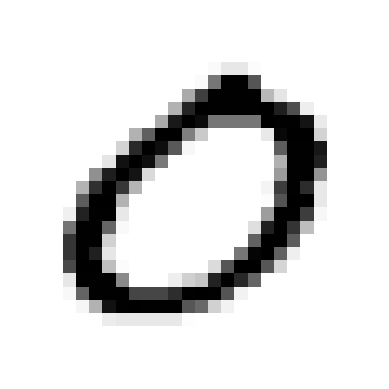

In [9]:
plt.imshow(some_digit_image, cmap=matplotlib.cm.binary, interpolation="nearest")
plt.axis("off")

In [10]:
y[random_index]

'0'

*Разделим данные на обучающую выборку и испытательный набор.*

In [11]:
X_train, X_test, y_train, y_test = X[:60000], X[60000:], y[:60000], y[60000:]

*И перемешаем обучающую выборку.*

In [12]:
import numpy as np

In [13]:
shaffle_index = np.random.permutation(60000)
X_train, y_train = X_train[shaffle_index], y_train[shaffle_index]

## **Обучение двоичного классификатора.**

*Научим модель классифицировать тройки и "не тройки".*

In [14]:
y_train  # В датасете строки

array(['6', '7', '9', ..., '8', '4', '1'], shape=(60000,), dtype=object)

In [15]:
y_train_3 = (y_train == "3")
y_test_3 = (y_test == "3")

*Воспользуемся классификатором на основе метода стохастического градиентного спуска - `SGDClassifier`, который способен обрабатывать огромные наборы данных, по одному образцу за раз (подходит для динамического обучения).*

In [16]:
from sklearn.linear_model import SGDClassifier

In [17]:
sgd_clf = SGDClassifier(random_state=42)
sgd_clf.fit(X_train, y_train_3)

,"random_state random_state: int, RandomState instance, default=NoneUsed for shuffling the data, when ``shuffle`` is set to ``True``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.Integer values must be in the range `[0, 2**32 - 1]`.",42
,"<a class=""param-doc-link"" style=""anchor-name: --doc-link-loss;"" rel=""noreferrer"" target=""_blank"" href=""https://scikit-learn.org/1.9/modules/generated/sklearn.linear_model.SGDClassifier.html#:~:text=loss,-%7B%27hinge%27%2C%20%27log_loss%27%2C%20%27modified_huber%27%2C%20%27squared_hinge%27%2C%20%20%20%20%20%20%20%20%27perceptron%27%2C%20%27squared_error%27%2C%20%27huber%27%2C%20%27epsilon_insensitive%27%2C%20%20%20%20%20%20%20%20%27squared_epsilon_insensitive%27%7D%2C%20default%3D%27hinge%27""> loss loss: {'hinge', 'log_loss', 'modified_huber', 'squared_hinge', 'perceptron', 'squared_error', 'huber', 'epsilon_insensitive', 'squared_epsilon_insensitive'}, default='hinge'The loss function to be used.- 'hinge' gives a linear SVM.- 'log_loss' gives logistic regression, a probabilistic classifier.- 'modified_huber' is another smooth loss that brings tolerance to outliers as well as probability estimates.- 'squared_hinge' is like hinge but is quadratically penalized.- 'perceptron' is the linear loss used by the perceptron algorithm.- The other losses, 'squared_error', 'huber', 'epsilon_insensitive' and 'squared_epsilon_insensitive' are designed for regression but can be useful in classification as well; see :class:`~sklearn.linear_model.SGDRegressor` for a description.More details about the losses formulas can be found in the :ref:`User Guide<sgd_mathematical_formulation>` and you can find a visualisation of the lossfunctions in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_loss_functions.py`.",'hinge'
,"penalty penalty: {'l2', 'l1', 'elasticnet', None}, default='l2'The penalty (aka regularization term) to be used. Defaults to 'l2'which is the standard regularizer for linear SVM models. 'l1' and'elasticnet' might bring sparsity to the model (feature selection)not achievable with 'l2'. No penalty is added when set to `None`.You can see a visualisation of the penalties in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_penalties.py`.",'l2'
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term. The higher thevalue, the stronger the regularization. Also used to compute thelearning rate when `learning_rate` is set to 'optimal'.Values must be in the range `[0.0, inf)`.",0.0001
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with 0 <= l1_ratio <= 1.l1_ratio=0 corresponds to L2 penalty, l1_ratio=1 to L1.Only used if `penalty` is 'elasticnet'.Values must be in the range `[0.0, 1.0]` or can be `None` if`penalty` is not `elasticnet`... versionchanged:: 1.7 `l1_ratio` can be `None` when `penalty` is not ""elasticnet"".",0.15
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method.Values must be in the range `[1, inf)`... versionadded:: 0.19",1000
,"tol tol: float or None, default=1e-3The stopping criterion. If it is not None, training will stopwhen (loss > best_loss - tol) for ``n_iter_no_change`` consecutiveepochs.Convergence is checked against the training loss or thevalidation loss depending on the `early_stopping` parameter.Values must be in the range `[0.0, inf)`... versionadded:: 0.19",0.001
,"shuffle shuffle: bool, default=TrueWhether or not the training data should be shuffled after each epoch.",True
,"verbose verbose: int, default=0The verbosity level.Values must be in the range `[0, inf)`.",0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-insensitive loss functions; only i

In [18]:
sgd_clf.predict([some_digit])

array([False])

## **Показатели производительности.**

*Реализуем перекрёстную проверку для модели классификации самостоятельно.*

In [19]:
from sklearn.model_selection import StratifiedKFold
from sklearn.base import clone

In [20]:
skfolds = StratifiedKFold(n_splits=3, random_state=42, shuffle=True)

*Непосредственно код-аналог `cross_val_score()`.*

In [21]:
for train_index, test_index in skfolds.split(X_train, y_train_3):
    clone_clf = clone(sgd_clf)
    X_train_folds = X_train[train_index]
    y_train_folds = y_train_3[train_index]
    X_test_folds = X_train[train_index]
    y_test_folds = y_train_3[train_index]

    clone_clf.fit(X_train_folds, y_train_folds)
    y_pred = clone_clf.predict(X_test_folds)
    n_correct = sum(y_pred == y_test_folds)
    print(n_correct / len(y_pred))

0.94015
0.969475
0.927175


*Далее перекрёсная проверка по K блокам, то есть разбиение обучающего набора на K блоков (в данном случае 3), выработку прогнозов и их оценку на каждом блоке с использованием модели, обученной на остальных блоках.*

In [22]:
from sklearn.model_selection import cross_val_score

In [23]:
cross_val_score(sgd_clf, X_train, y_train_3, cv=3, scoring="accuracy")

array([0.9572 , 0.96365, 0.93895])

*Точность ~95% - подозрительно много. Посмотрим на точность классификатора, который всегда выдаёт False.*

In [24]:
from sklearn.base import BaseEstimator

In [25]:
class Never3Classifier(BaseEstimator):
    def fit(self, X, y=None):
        pass
    def predict(self, X):
        return np.zeros(len(X), 1, dtype=bool)

In [26]:
never_3_clf = Never3Classifier()

In [27]:
cross_val_score(sgd_clf, X_train, y_train_3, cv=3, scoring="accuracy")

array([0.9572 , 0.96365, 0.93895])

*Оценка даже так очень высока. Проблема в том, что троек в датасете мало - ~10%, оттого и такая точность - ~90% случаев действительно не тройки. Такая проверка для классификаторов не подходит.*

*Посмотрим на **матрицу неточностей** - подсчёт количества неверных предсказаний для конкретного образца. Для этого нужно иметь предсказания.*

In [28]:
from sklearn.model_selection import cross_val_predict

In [29]:
y_train_pred = cross_val_predict(sgd_clf, X_train, y_train_3, cv=3)

*Вместо сумм очков оценки, как `cross_val_score()`, `cross_val_predict()` возвращает прогнозы, выработанные на каждом испытательном блоке.*

In [30]:
from sklearn.metrics import confusion_matrix

In [31]:
confusion_matrix(y_train_3, y_train_pred)

array([[51815,  2054],
       [  750,  5381]])

*Результаты трактуются так:*
- *51436 - слева сверху количество не троек, которые были верно классифицированны, как не тройки (истинно отрицательные классификации, true negative - TN),*
- *2433 - справа сверху - не тройки, которые были ошибочно предсказаны, как тройки (ложноположительные классификации, false positive - FP),*
- *769 - слева снизу - тройки, которые неверно классифицированны, как не тройки (ложноотрицательные классификации, false negative - FN),*
- *5362 - справа снизу - тройки, которые были верно выбраны, как тройки (истинно положительные классификации, true positive - TP).*

*Для идеального классификатора матрица выглядела бы вот так.*

In [32]:
y_train_perfect_predictions = y_train_3

In [33]:
confusion_matrix(y_train_3, y_train_perfect_predictions)

array([[53869,     0],
       [    0,  6131]])

## **Точность (`precision`) и полнота (`recall`).**

$$
\text{Точность} = \frac{TP}{TP + FP}
$$

$$
\text{Полнота} = \frac{TP}{TP + FN}
$$

In [34]:
from sklearn.metrics import precision_score, recall_score

In [35]:
precision_score(y_train_3, y_train_pred)

0.7237390719569603

In [36]:
recall_score(y_train_3, y_train_pred)

0.8776708530419182

***Среднее гармоническое** точности и полноты - мера F1.*

$$
F_1 = \frac{2}{\frac{1}{\text{точность}} + \frac{1}{\text{полнота}}} = 2 * \frac{\text{точность} * \text{полнота}}{\text{точность} + \text{полнота}} = \frac{TP}{TP + \frac{FN + FP}{2}}
$$

In [37]:
from sklearn.metrics import f1_score

In [38]:
f1_score(y_train_3, y_train_pred)

0.7933067964027717

*С увеличением точности уменьшается полнота и наоборот. На порог (по умолчанию он - 0), от которого зависит и точность, и полнота можно "повлиять" только так.*

In [39]:
y_scores = sgd_clf.decision_function([some_digit])  # Сумма очков для образца, показанного выше (8)
y_scores

array([-5594.9678729])

In [40]:
threshold = 0
some_digit_pred = (y_scores > threshold)  # Предсказание ложное, так как сумма очков меньше заданного порога
some_digit_pred

array([False])

In [41]:
threshold = -20000
some_digit_pred = (y_scores > threshold)  # Предсказание истинно, так как сумма очков больше заданного порога
some_digit_pred

array([ True])

## **Кривая точности - полноты.**

*Поймём какой порог лучше использовать.*

In [42]:
y_scores = cross_val_predict(sgd_clf, X_train, y_train_3, cv=3, method="decision_function")

In [43]:
from sklearn.metrics import precision_recall_curve

In [44]:
precisions, recalls, thresholds = precision_recall_curve(y_train_3, y_scores)

In [45]:
def plot_precision_recall_vs_threshold(precisions, recalls, thresholds):
    plt.plot(thresholds, precisions[:-1], "b--", label="Точность")
    plt.plot(thresholds, recalls[:-1], "g-", label="Полнота")
    plt.xlabel("Порог")
    plt.legend(loc="center left")
    plt.ylim([0, 1])
    # plt.xlim([-700000, 700000])

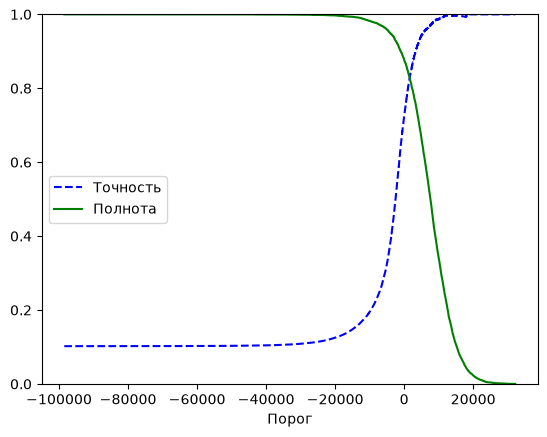

In [46]:
plot_precision_recall_vs_threshold(precisions, recalls, thresholds)

In [47]:
def plot_precision_vs_recall(precisions, recalls):
    plt.plot(recalls, precisions)
    plt.xlabel("Полнота")
    plt.ylabel("Точность")
    plt.grid()

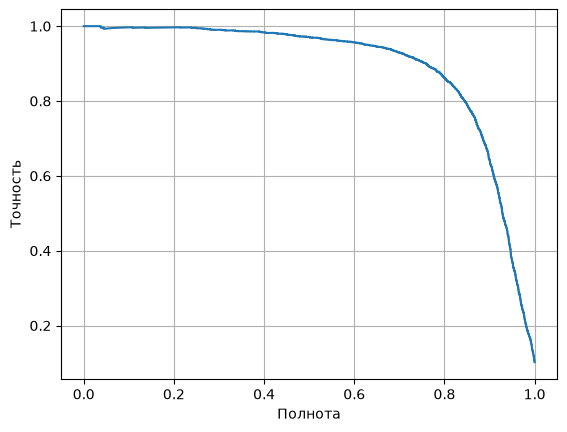

In [48]:
plot_precision_vs_recall(precisions, recalls)

In [49]:
y_train_pred_better = (y_scores > -1000)

In [50]:
precision_score(y_train_3, y_train_pred_better)

0.6423833352728966

In [51]:
recall_score(y_train_3, y_train_pred_better)

0.9003425216114826

## **Кривая рабочей характеристики приёмника (Receiver Operating Characteristic - ROC).**

*Показывает полноту по отношению к доле ложноположительных классификаций (False Positive Rate - FPR) - пропорция отрицательных образцов, которые были некорректно классифицированы как положительные, равна единице минут доля истинно отрицательных классификаций (True Negative Rate - TNR) - пропорция отрицательных образцов, которые были корректно классифицированны как отрицательные.*

*Доля TNR называется специфичностью (`specificity`). То есть ROC показывает полноту в сравнении с $1 - \text{специфичность}$.*

In [52]:
from sklearn.metrics import roc_curve

In [53]:
fpr, tpr, thresholds = roc_curve(y_train_3, y_scores)

In [54]:
def plot_roc_curve(fpr, tpr, label=None):
    plt.plot(fpr, tpr, linewidth=2, label=label)
    plt.plot([0, 1], [0, 1], "k--")  # y = x - чисто случайный классификатор
    plt.axis([0, 1, 0, 1])
    plt.xlabel("False Positive Rate")
    plt.xlabel("True Positive Rate")

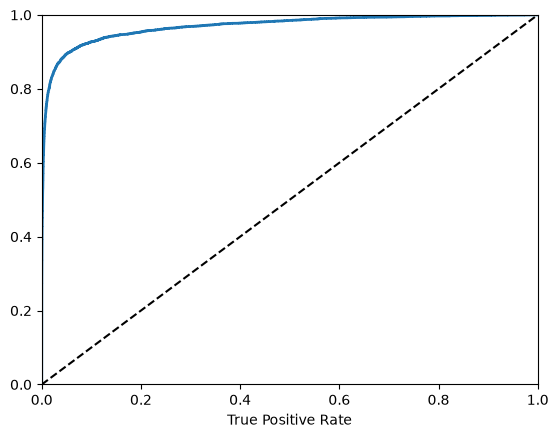

In [55]:
plot_roc_curve(fpr, tpr)

*Чем выше полнота (TPR), тем больше классификатор даёт ложноположительных классификаций (FPR). Хороший классификатор отдаляется от указанной линии настолько далеко, насколько это возможно.*

*Классификаторы можно сравнить площадью под кривой (Area Under the Curve - AUC), ROC AUC = 1 - безупречный, ROC AUC = 0.5 - случайный.*

In [56]:
from sklearn.metrics import roc_auc_score

In [57]:
roc_auc_score(y_train_3, y_scores)

0.9694386188300446

*Эмпирическое правило: когда положительный класс является редким или ложноположительные классификации заботят больше, чем ложноотрицательные, выбираем кривую PR, иначе - ROC.*

## **Обучим `RandomForestClassifier` и сравним кривую ROC и показатель ROC AUC с классификатором `SGDClassifier`.**

*`RandomForestClassifier` не имеет метода `decision_function()`, но есть `predict_proba()`, который возвращает массив, который содержит строку на образец и столбец на класс, содержащий вероятность того, что заданный образец принадлежит заданному классу.*

In [58]:
from sklearn.ensemble import RandomForestClassifier

In [59]:
forest_clf = RandomForestClassifier(random_state=42)

In [60]:
y_probas_forest = cross_val_predict(forest_clf, X_train, y_train_3, cv=3, method="predict_proba")

*Достанем **показатели**, так как нужны они, а не вероятности.*

In [61]:
y_scores_forest = y_probas_forest[:, 1]
fpr_forest, tpr_forest, thresholds_forest = roc_curve(y_train_3, y_scores_forest)

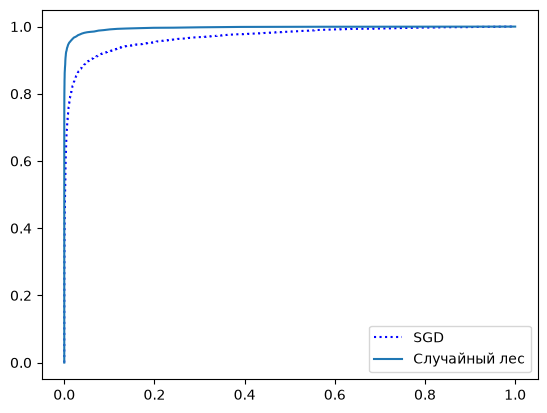

In [62]:
plt.plot(fpr, tpr, "b:", label = "SGD")
plt.plot(fpr_forest, tpr_forest, label = "Случайный лес")
plt.legend(loc="lower right")

*Случайный лес выглядит лучше.*

In [63]:
roc_auc_score(y_train_3, y_scores_forest)

0.9961489969751766

In [64]:
y_train_pred = cross_val_predict(forest_clf, X_train, y_train_3, cv=3)

In [65]:
precision_score(y_train_3, y_train_pred)

0.9941804073714839

In [66]:
recall_score(y_train_3, y_train_pred)

0.8359158375468928

*Все показатели отличные!*

## **Многоклассовая классификация.**

*Обучим классификатор стратегией OvA - по умолчанию `Scikit-Learn` старается применять такую стратегию, кроме **метода опорных векторов** (обучаем для каждого класса свой классификатор и выводим баллы за каждый класс).*

In [67]:
sgd_clf.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance, default=NoneUsed for shuffling the data, when ``shuffle`` is set to ``True``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.Integer values must be in the range `[0, 2**32 - 1]`.",42
,"<a class=""param-doc-link"" style=""anchor-name: --doc-link-loss;"" rel=""noreferrer"" target=""_blank"" href=""https://scikit-learn.org/1.9/modules/generated/sklearn.linear_model.SGDClassifier.html#:~:text=loss,-%7B%27hinge%27%2C%20%27log_loss%27%2C%20%27modified_huber%27%2C%20%27squared_hinge%27%2C%20%20%20%20%20%20%20%20%27perceptron%27%2C%20%27squared_error%27%2C%20%27huber%27%2C%20%27epsilon_insensitive%27%2C%20%20%20%20%20%20%20%20%27squared_epsilon_insensitive%27%7D%2C%20default%3D%27hinge%27""> loss loss: {'hinge', 'log_loss', 'modified_huber', 'squared_hinge', 'perceptron', 'squared_error', 'huber', 'epsilon_insensitive', 'squared_epsilon_insensitive'}, default='hinge'The loss function to be used.- 'hinge' gives a linear SVM.- 'log_loss' gives logistic regression, a probabilistic classifier.- 'modified_huber' is another smooth loss that brings tolerance to outliers as well as probability estimates.- 'squared_hinge' is like hinge but is quadratically penalized.- 'perceptron' is the linear loss used by the perceptron algorithm.- The other losses, 'squared_error', 'huber', 'epsilon_insensitive' and 'squared_epsilon_insensitive' are designed for regression but can be useful in classification as well; see :class:`~sklearn.linear_model.SGDRegressor` for a description.More details about the losses formulas can be found in the :ref:`User Guide<sgd_mathematical_formulation>` and you can find a visualisation of the lossfunctions in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_loss_functions.py`.",'hinge'
,"penalty penalty: {'l2', 'l1', 'elasticnet', None}, default='l2'The penalty (aka regularization term) to be used. Defaults to 'l2'which is the standard regularizer for linear SVM models. 'l1' and'elasticnet' might bring sparsity to the model (feature selection)not achievable with 'l2'. No penalty is added when set to `None`.You can see a visualisation of the penalties in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_penalties.py`.",'l2'
,"alpha alpha: float, default=0.0001Constant that multiplies the regularization term. The higher thevalue, the stronger the regularization. Also used to compute thelearning rate when `learning_rate` is set to 'optimal'.Values must be in the range `[0.0, inf)`.",0.0001
,"l1_ratio l1_ratio: float, default=0.15The Elastic Net mixing parameter, with 0 <= l1_ratio <= 1.l1_ratio=0 corresponds to L2 penalty, l1_ratio=1 to L1.Only used if `penalty` is 'elasticnet'.Values must be in the range `[0.0, 1.0]` or can be `None` if`penalty` is not `elasticnet`... versionchanged:: 1.7 `l1_ratio` can be `None` when `penalty` is not ""elasticnet"".",0.15
,"fit_intercept fit_intercept: bool, default=TrueWhether the intercept should be estimated or not. If False, thedata is assumed to be already centered.",True
,"max_iter max_iter: int, default=1000The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the ``fit`` method, and not the:meth:`partial_fit` method.Values must be in the range `[1, inf)`... versionadded:: 0.19",1000
,"tol tol: float or None, default=1e-3The stopping criterion. If it is not None, training will stopwhen (loss > best_loss - tol) for ``n_iter_no_change`` consecutiveepochs.Convergence is checked against the training loss or thevalidation loss depending on the `early_stopping` parameter.Values must be in the range `[0.0, inf)`... versionadded:: 0.19",0.001
,"shuffle shuffle: bool, default=TrueWhether or not the training data should be shuffled after each epoch.",True
,"verbose verbose: int, default=0The verbosity level.Values must be in the range `[0, inf)`.",0
,"epsilon epsilon: float, default=0.1Epsilon in the epsilon-insensitive loss functions; only i

In [68]:
sgd_clf.predict([some_digit])

array(['0'], dtype='<U1')

In [69]:
some_digit_scores = sgd_clf.decision_function([some_digit])
some_digit_scores

array([[ 12126.43320102, -53190.47671184, -10581.5812338 ,
         -8535.5042908 , -22285.00595335, -10483.58484488,
        -11949.26300906,  -9590.82359279,  -9299.27750297,
         -6246.13799916]])

*Элемент под индексом с наивысшим баллом = предсказание.*

In [70]:
np.argmax(some_digit_scores)

np.int64(0)

In [71]:
sgd_clf.classes_

array(['0', '1', '2', '3', '4', '5', '6', '7', '8', '9'], dtype='<U1')

In [72]:
sgd_clf.classes_[8]

np.str_('8')

*Теперь обучим OvO (обучение классификаторов для каждой пары классов и побеждает вариант выйгравший большую часть дуэлей). Количество таких классификаторов:*

$$
\frac{N * (N - 1)}{2}
$$

*В случае 10 классов - 45.*

In [73]:
from sklearn.multiclass import OneVsOneClassifier

In [74]:
ovo_clf = OneVsOneClassifier(SGDClassifier(random_state=42))

In [75]:
ovo_clf.fit(X_train, y_train)

,"estimator estimator: estimator objectA regressor or a classifier that implements :term:`fit`.When a classifier is passed, :term:`decision_function` will be usedin priority and it will fallback to :term:`predict_proba` if it is notavailable.When a regressor is passed, :term:`predict` is used.",SGDClassifier(random_state=42)
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation: the `n_classes * (n_classes - 1) / 2` OVO problems are computed in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
Name,Type,Value
classes_ classes_: numpy array of shape [n_classes]Array containing labels.,"ndarray[object](10,)","['0','1','2',...,'7','8','9']"
estimators_ estimators_: list of ``n_classes * (n_classes - 1) / 2`` estimatorsEstimators used for predictions.,tuple,"(SGDClassifier(random_state=42), SGDClassifier(random_state=42), SGDClassifier(random_state=42), SGDClassifier(random_state=42), ...)"
n_classes_ n_classes_: intNumber of classes.,int,10
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,784
"pairwise_indices_ pairwise_indices_: list, length = ``len(estimators_)``, or ``None``Indices of samples used when training the estimators.``None`` when ``estimator``'s `pairwise` tag is False.",NoneType,None
,"random_state random_state: int, RandomState instance, default=NoneUsed for shuffling the data, when ``shuffle`` is set to ``True``.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.Integer values must be in the range `[0, 2**32 - 1]`.",42
,"<a class=""param-doc-link"" style=""anchor-name: --doc-link-loss;"" rel=""noreferrer"" target=""_blank"" href=""https://scikit-learn.org/1.9/modules/generated/sklearn.linear_model.SGDClassifier.html#:~:text=loss,-%7B%27hinge%27%2C%20%27log_loss%27%2C%20%27modified_huber%27%2C%20%27squared_hinge%27%2C%20%20%20%20%20%20%20%20%27perceptron%27%2C%20%27squared_error%27%2C%20%27huber%27%2C%20%27epsilon_insensitive%27%2C%20%20%20%20%20%20%20%20%27squared_epsilon_insensitive%27%7D%2C%20default%3D%27hinge%27""> loss loss: {'hinge', 'log_loss', 'modified_huber', 'squared_hinge', 'perceptron', 'squared_error', 'huber', 'epsilon_insensitive', 'squared_epsilon_insensitive'}, default='hinge'The loss function to be used.- 'hinge' gives a linear SVM.- 'log_loss' gives logistic regression, a probabilistic classifier.- 'modified_huber' is another smooth loss that brings tolerance to outliers as well as probability estimates.- 'squared_hinge' is like hinge but is quadratically penalized.- 'perceptron' is the linear loss used by the perceptron algorithm.- The other losses, 'squared_error', 'huber', 'epsilon_insensitive' and 'squared_epsilon_insensitive' are designed for regression but can be useful in classification as well; see :class:`~sklearn.linear_model.SGDRegressor` for a description.More details about the losses formulas can be found in the :ref:`User Guide<sgd_mathematical_formulation>` and you can find a visualisation of the lossfunctions in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_loss_functions.py`.",'hinge'
,"penalty penalty: {'l2', 'l1', 'elasticnet', None}, default='l2'The penalty (aka regularization term) to be used. Defaults to 'l2'which is the standard regularizer for linear SVM models. 'l1' and'elasticnet' might bring sparsity to the model (feature selection)not achievable with 'l2'. No penalty is added when set to `None`.You can see a visualisation of the penalties in:ref:`sphx_glr_auto_examples_linear_model_plot_sgd_penalties.py`.",'l2'


In [76]:
ovo_clf.predict([some_digit])

array(['0'], dtype=object)

In [77]:
len(ovo_clf.estimators_)

45

In [78]:
forest_clf.fit(X_train, y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [79]:
forest_clf.predict([some_digit])

array(['0'], dtype=object)

In [80]:
forest_clf.predict_proba([some_digit])

array([[1., 0., 0., 0., 0., 0., 0., 0., 0., 0.]])

In [81]:
cross_val_score(sgd_clf, X_train, y_train, cv=3, scoring="accuracy")

array([0.87835, 0.8751 , 0.8717 ])

*Масштабируем данные.*

In [82]:
from sklearn.preprocessing import StandardScaler

In [83]:
scaler = StandardScaler()

In [84]:
X_train_scaled = scaler.fit_transform(X_train.astype(np.float64))

In [85]:
cross_val_score(sgd_clf, X_train_scaled, y_train, cv=3, scoring="accuracy")

d:\Dev\Learning\python_libraries_learning\venv\Lib\site-packages\sklearn\linear_model\_stochastic_gradient.py:741: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
d:\Dev\Learning\python_libraries_learning\venv\Lib\site-packages\sklearn\linear_model\_stochastic_gradient.py:741: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
d:\Dev\Learning\python_libraries_learning\venv\Lib\site-packages\sklearn\linear_model\_stochastic_gradient.py:741: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


array([0.9022 , 0.90135, 0.9058 ])

## **Анализ ошибок.**

In [86]:
y_train_pred = cross_val_predict(sgd_clf, X_train_scaled, y_train, cv=3)

d:\Dev\Learning\python_libraries_learning\venv\Lib\site-packages\sklearn\linear_model\_stochastic_gradient.py:741: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
d:\Dev\Learning\python_libraries_learning\venv\Lib\site-packages\sklearn\linear_model\_stochastic_gradient.py:741: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(
d:\Dev\Learning\python_libraries_learning\venv\Lib\site-packages\sklearn\linear_model\_stochastic_gradient.py:741: ConvergenceWarning: Maximum number of iteration reached before convergence. Consider increasing max_iter to improve the fit.
  warnings.warn(


*Здесь на главной диагонали количество верно классифицированных классов.*

In [87]:
conf_mx = confusion_matrix(y_train, y_train_pred)
conf_mx

array([[5608,    0,   19,    7,    8,   52,   34,    6,  188,    1],
       [   0, 6419,   43,   21,    3,   42,    5,    7,  189,   13],
       [  27,   28, 5283,   83,   70,   24,   73,   38,  320,   12],
       [  25,   18,  121, 5259,    1,  217,   23,   40,  362,   65],
       [  12,   16,   54,   11, 5247,   11,   36,   20,  275,  160],
       [  23,   18,   37,  165,   48, 4521,   81,   17,  450,   61],
       [  31,   16,   55,    2,   42,   95, 5561,    4,  112,    0],
       [  21,   13,   55,   24,   49,   10,    4, 5718,  153,  218],
       [  18,   71,   46,   85,    2,  129,   33,    9, 5405,   53],
       [  21,   21,   29,   53,  129,   39,    1,  189,  301, 5166]])

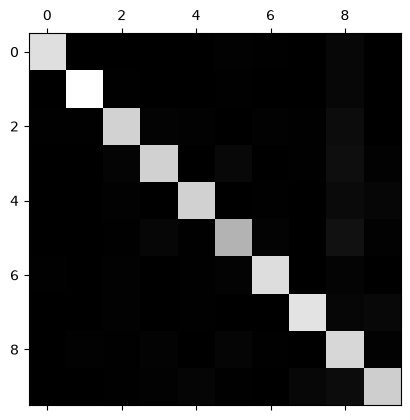

In [88]:
plt.matshow(conf_mx, cmap=plt.cm.grey)

*Посмотрим на матрицу с частотой ошибок (разделим каждое верное предсказание на количество объектов).*

In [89]:
row_sums = conf_mx.sum(axis=1, keepdims=True)
norm_conf_mx = conf_mx / row_sums

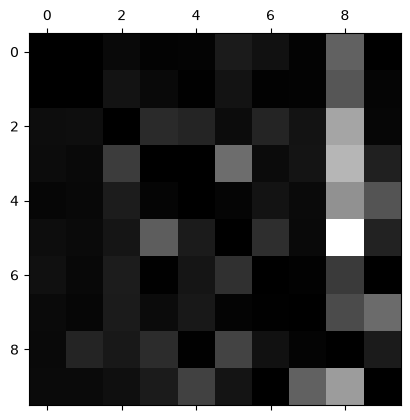

In [90]:
np.fill_diagonal(norm_conf_mx, 0)
plt.matshow(norm_conf_mx, cmap=plt.cm.grey)

*Строки - фактические классы, столбцы - спрогнозированные классы. И из матрицы видно, что другие классы были часто неверно предсказаны, как восьмёрки. Причём ошибки не симметричны относительно главной диагонали.*

In [91]:
def plot_digits(instances, images_per_row=10, **options):
    size = 28
    images_per_row = min(len(instances), images_per_row)
    images = [instance.reshape(size,size) for instance in instances]
    n_rows = (len(instances) - 1) // images_per_row + 1
    row_images = []
    n_empty = n_rows * images_per_row - len(instances)
    images.append(np.zeros((size, size * n_empty)))
    for row in range(n_rows):
        rimages = images[row * images_per_row : (row + 1) * images_per_row]
        row_images.append(np.concatenate(rimages, axis=1))
    image = np.concatenate(row_images, axis=0)
    plt.imshow(image, cmap = plt.cm.binary, **options)
    plt.axis("off")

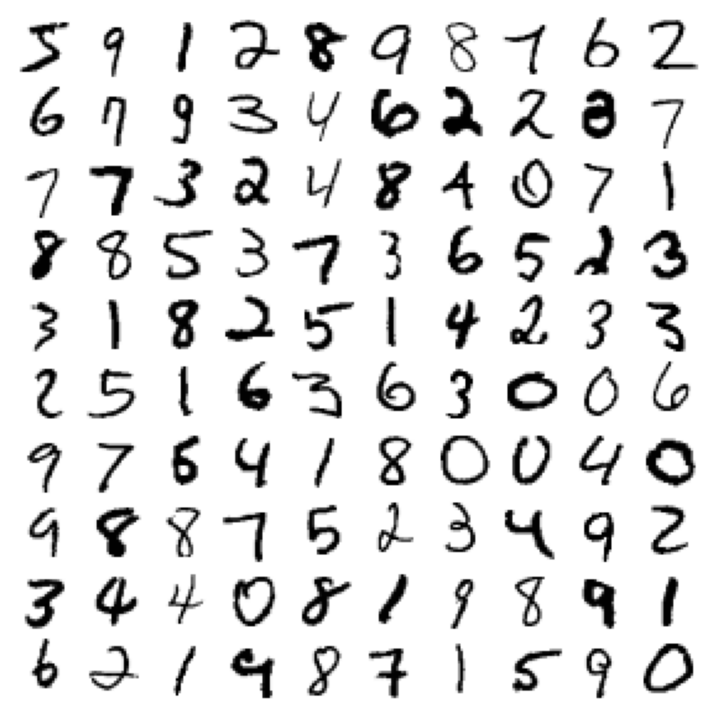

In [92]:
plt.figure(figsize=(9,9))
example_images = np.r_[X[:12000:600], X[13000:30600:600], X[30600:60000:590]]
plot_digits(example_images, images_per_row=10)

*Теперь выведем числа 3 и 5 расположив их в зависимости от предположения модели.*

In [93]:
cl_a, cl_b = "3", "5"
X_aa = X_train[(y_train == cl_a) & (y_train_pred == cl_a)]
X_ab = X_train[(y_train == cl_a) & (y_train_pred == cl_b)]
X_ba = X_train[(y_train == cl_b) & (y_train_pred == cl_a)]
X_bb = X_train[(y_train == cl_b) & (y_train_pred == cl_b)]

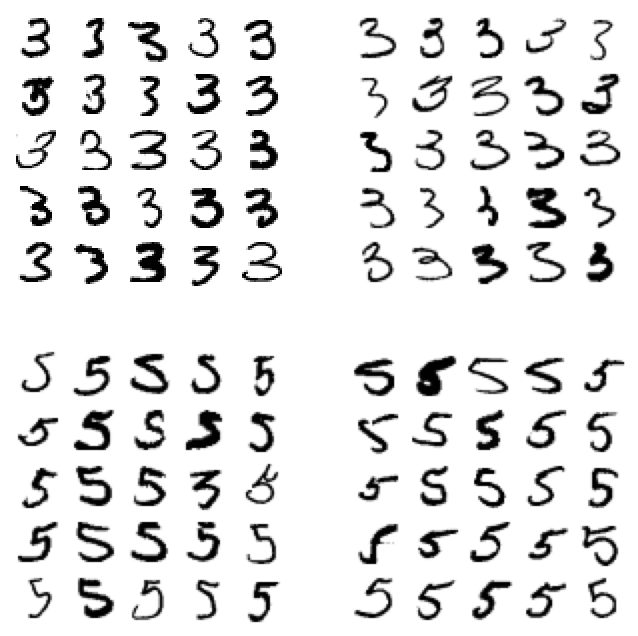

In [94]:
plt.figure(figsize=(8, 8))
plt.subplot(221); plot_digits(X_aa[:25], images_per_row=5)
plt.subplot(222); plot_digits(X_ab[:25], images_per_row=5)
plt.subplot(223); plot_digits(X_ba[:25], images_per_row=5)
plt.subplot(224); plot_digits(X_bb[:25], images_per_row=5)

*Здесь два блока слева - изображения классифицированные, как тройки, а справа - как пятёрки. По ним можно сделать вывод, что линейный `SGDClassifier` не слишком подходит для данной задачи.*

## **Многозначная классификация.**

*Например, для задачи распознавания лиц на изображениях нам нужно прекреплять прегноз модели на каждую особу в кадре. Посмотрим на пример многозначной крассификации на числах.*

In [95]:
from sklearn.neighbors import KNeighborsClassifier

In [96]:
y_train_large = (y_train.astype(np.int64) >= 7)  # Больше 7
y_train_odd = (y_train.astype(np.int64) % 2 != 0)  # Нечётное
y_multilabel = np.c_[y_train_large, y_train_odd]

In [97]:
knn_clf = KNeighborsClassifier()

In [98]:
knn_clf.fit(X_train, y_multilabel)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier",list,"[array([False, True]), array([False, True])]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [99]:
knn_clf.predict([some_digit])

array([[False, False]])

*Посчитаем среднюю меру F1 по всем меткам.*

In [100]:
y_train_knn_pred = cross_val_predict(knn_clf, X_train, y_multilabel, cv=3)

In [101]:
f1_score(y_multilabel, y_train_knn_pred, average="macro")

0.9764686961929583

*Здесь степень важности у всех одинаковая, однако можно её изменить и дать более важной метке больший вес, например, дать каждой метке вес равной её **поддержке** (количеству образцов с такой целевой меткой). Для этого нужно установить `average="weighted"`.*

## **Многовыходовая классификация.**

***Многовыходовая-многозначкой классификация** - обобщение многозначной классификации, где каждая метка может быть многоклассовой (иметь более двух значений).*

*Создадим модель, которая будет способна очищать от шума изображения MNIST.*

*Сначала добавим шум к изображениям.*

In [102]:
noise = np.random.randint(0, 100, (len(X_train), 784))
X_train_mod = X_train + noise

In [103]:
noise = np.random.randint(0, 100, (len(X_test), 784))
X_test_mod = X_test + noise

In [104]:
y_train_mod = X_train
y_test_mod = X_test

In [105]:
def plot_digit(data):
    image = data.reshape(28, 28)
    plt.imshow(image, cmap = plt.cm.binary,
               interpolation="nearest")
    plt.axis("off")

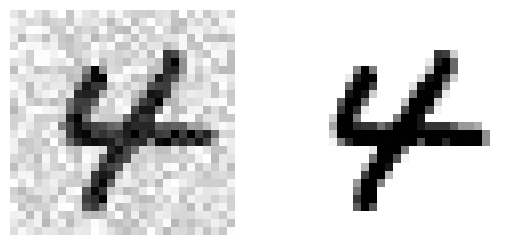

In [106]:
some_index = 5500
plt.subplot(121); plot_digit(X_test_mod[some_index])
plt.subplot(122); plot_digit(y_test_mod[some_index])

*Получилось наглядно - зашумлённое изображение и целевое.*

In [107]:
knn_clf.fit(X_train_mod, y_train_mod)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier",list,"[array([0]), array([0]), array([0]), array([0]), ...]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [108]:
clean_digit = knn_clf.predict([X_test_mod[some_index]])

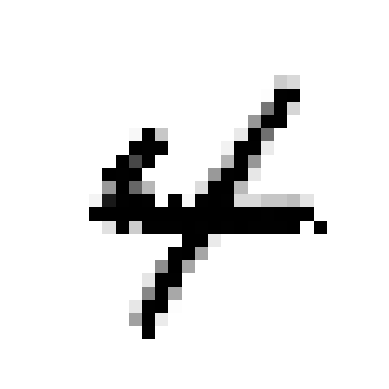

In [109]:
plot_digit(clean_digit)

*Получилось неплохо очистить.*

Упражнения к этой главе доступны в папке: `scikit_learn\guide\base_ML_book\chapter_3\tasks`.